# Correlazioni con le proprietà di C — plot

Al variare di a = ρα (ρ autovalore principale di C; in-degree medio per C nilpotente):
- (a) correlazione fra l'autovettore principale di C e Q, CQ (solo C classica: per C nilpotente l'autovettore non è definito)
- (b) correlazione fra il numero di input N_1 e Q, CQ

Una figura per risoluzione (stesso asse y per 4 e 6 digits, da affiancare in LaTeX).
Colore = grandezza; linea piena = Pearson, tratteggiata = Spearman; linea verticale in a = 1.
Legge `results/correlazioni_autovettore_C/{C_TYPE}/{ALGO}/scan_a_{res}_digits.parquet`,
prodotti dalla sezione "SCAN IN a" di `notebooks/data_generation/C_correlations.ipynb`.
Figure in PDF in `figures/correlazioni_autovettore_C/{C_TYPE}/{ALGO}/`.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = next(p for p in [Path().resolve(), *Path().resolve().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))

from src.plotting import (set_style, figsize, save_fig, two_part_legend, common_ylim,
                          SINGLE, HALF, PALETTE, RES_MARKER, SEQ_CMAP, SYMBOLS)
from src.plotting import load_stability, check_eta0, plot_stability, plot_corr_vs_order

set_style()
from src.plotting import plot_corr_vs_a

## Configurazione

In [2]:
C_TYPE = "C_classica"                        # "C_classica" | "C_nilpotente"
ALGO   = "extended_fitness_with_imports"     # "extended_fitness_with_imports" | "extended_eci_with_imports"
RESOLUTIONS = [4, 6]
QUANTITIES = ["Q", "CQ"]

DATA_DIR = ROOT / "results" / "correlazioni_autovettore_C" / C_TYPE / ALGO
SAVE_FIGS = True
FIG_DIR = ROOT / "plots" / "correlazioni_autovettore_C" / C_TYPE / ALGO

# (target) -> {"ylim": (min, max), "legend": {kwargs di ax.legend}} per ritocchi a mano
OVERRIDES = {}

## Caricamento

In [3]:
TARGETS = {
    "autovett": r"$r\,(u,\, X)$",       # v_1 = autovettore principale di C
    "n_inputs": r"$r\,(N_1,\, X)$",       # N_1 = numero di input
}

def select(df, target):
    """Colonne {metodo}_{target}_{X} -> {metodo}_{X}, per le funzioni di plot."""
    keep = ["a"] + [c for c in df if f"_{target}_" in c]
    return df[keep].rename(columns=lambda c: c.replace(f"_{target}_", "_"))

scans = {}
for res in RESOLUTIONS:
    f = DATA_DIR / f"scan_a_{res}_digits.parquet"
    if f.exists():
        scans[res] = pd.read_parquet(f)
        print(f"{res} digits: {len(scans[res])} valori di a, rho = {scans[res]['rho'].iloc[0]:.2f}")
    else:
        print(f"[manca] {f.relative_to(ROOT)}")

4 digits: 25 valori di a, rho = 34.68
6 digits: 25 valori di a, rho = 94.39


## Plot (a) autovettore principale e (b) numero di input

autovett — 4 digits


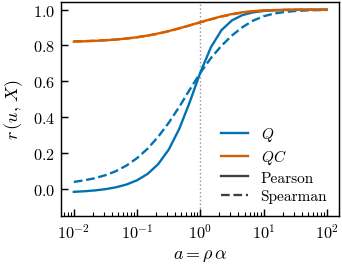

autovett — 6 digits


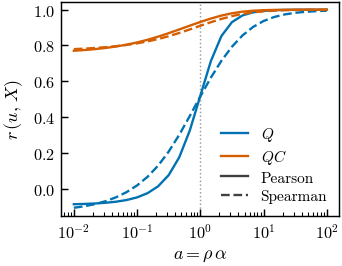

n_inputs — 4 digits


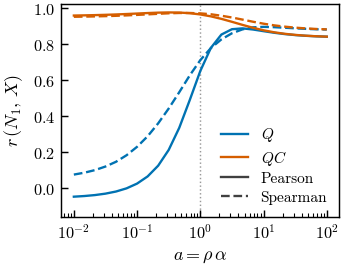

n_inputs — 6 digits


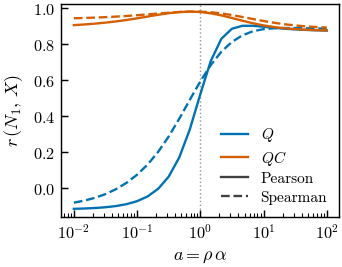

In [4]:
for target, ylabel in TARGETS.items():
    tables = {res: select(df, target) for res, df in scans.items()}
    tables = {res: t for res, t in tables.items() if t.drop(columns="a").notna().any().any()}
    if not tables:
        print(f"{target}: nessun dato (per C nilpotente l'autovettore principale non e' definito)")
        continue
    cols = [c for t in tables.values() for c in t.columns if c != "a"]
    ov = OVERRIDES.get(target, {})
    ylim = ov.get("ylim") or common_ylim(list(tables.values()), cols)    # stesso asse y per 4 e 6 digits
    for res, t in tables.items():
        print(f"{target} — {res} digits")
        plot_corr_vs_a(t, QUANTITIES, ylabel, ylim=ylim, legend_kw=ov.get("legend"),
                       save_path=FIG_DIR / f"{target}_{res}_digits" if SAVE_FIGS else None)